In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv("/content/SeoulBikeData.csv", encoding="ISO-8859-1")

In [ ]:
df.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [ ]:
df.tail()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
8755,30/11/2018,1003,19,4.2,34,2.6,1894,-10.3,0.0,0.0,0.0,Autumn,No Holiday,Yes
8756,30/11/2018,764,20,3.4,37,2.3,2000,-9.9,0.0,0.0,0.0,Autumn,No Holiday,Yes
8757,30/11/2018,694,21,2.6,39,0.3,1968,-9.9,0.0,0.0,0.0,Autumn,No Holiday,Yes
8758,30/11/2018,712,22,2.1,41,1.0,1859,-9.8,0.0,0.0,0.0,Autumn,No Holiday,Yes
8759,30/11/2018,584,23,1.9,43,1.3,1909,-9.3,0.0,0.0,0.0,Autumn,No Holiday,Yes


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       8760 non-null   object 
 1   Rented Bike Count          8760 non-null   int64  
 2   Hour                       8760 non-null   int64  
 3   Temperature(°C)            8760 non-null   float64
 4   Humidity(%)                8760 non-null   int64  
 5   Wind speed (m/s)           8760 non-null   float64
 6   Visibility (10m)           8760 non-null   int64  
 7   Dew point temperature(°C)  8760 non-null   float64
 8   Solar Radiation (MJ/m2)    8760 non-null   float64
 9   Rainfall(mm)               8760 non-null   float64
 10  Snowfall (cm)              8760 non-null   float64
 11  Seasons                    8760 non-null   object 
 12  Holiday                    8760 non-null   object 
 13  Functioning Day            8760 non-null   objec

In [ ]:
df.describe()

,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm)
count,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,704.602055,11.500000,12.882922,58.226256,1.724909,1436.825799,4.073813,0.569111,0.148687,0.075068
std,644.997468,6.922582,11.944825,20.362413,1.036300,608.298712,13.060369,0.868746,1.128193,0.436746
min,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000
25%,191.000000,5.750000,3.500000,42.000000,0.900000,940.000000,-4.700000,0.000000,0.000000,0.000000
50%,504.500000,11.500000,13.700000,57.000000,1.500000,1698.000000,5.100000,0.010000,0.000000,0.000000
75%,1065.250000,17.250000,22.500000,74.000000,2.300000,2000.000000,14.800000,0.930000,0.000000,0.000000
max,3556.000000,23.000000,39.400000,98.000000,7.400000,2000.000000,27.200000,3.520000,35.000000,8.800000


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
Date,0
Rented Bike Count,0
Hour,0
Temperature(°C),0
Humidity(%),0
Wind speed (m/s),0
Visibility (10m),0
Dew point temperature(°C),0
Solar Radiation (MJ/m2),0
Rainfall(mm),0


In [ ]:
df.columns = df.columns.str.strip()

for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].mean())

for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].fillna(df[col].mode()[0])

df.isnull().sum()

,0
Date,0
Rented Bike Count,0
Hour,0
Temperature(°C),0
Humidity(%),0
Wind speed (m/s),0
Visibility (10m),0
Dew point temperature(°C),0
Solar Radiation (MJ/m2),0
Rainfall(mm),0


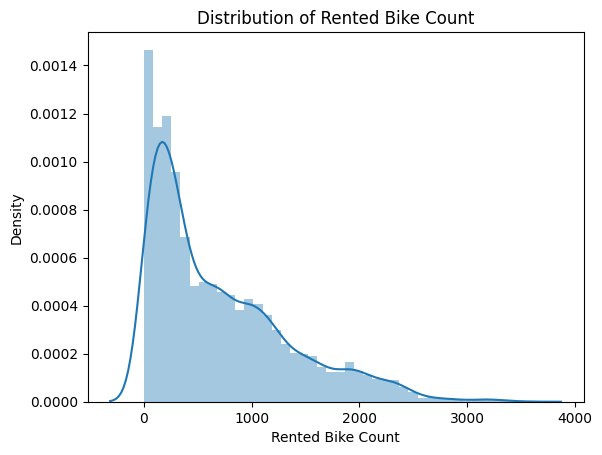

In [ ]:
sns.distplot(df['Rented Bike Count'])
plt.title("Distribution of Rented Bike Count")
plt.show()

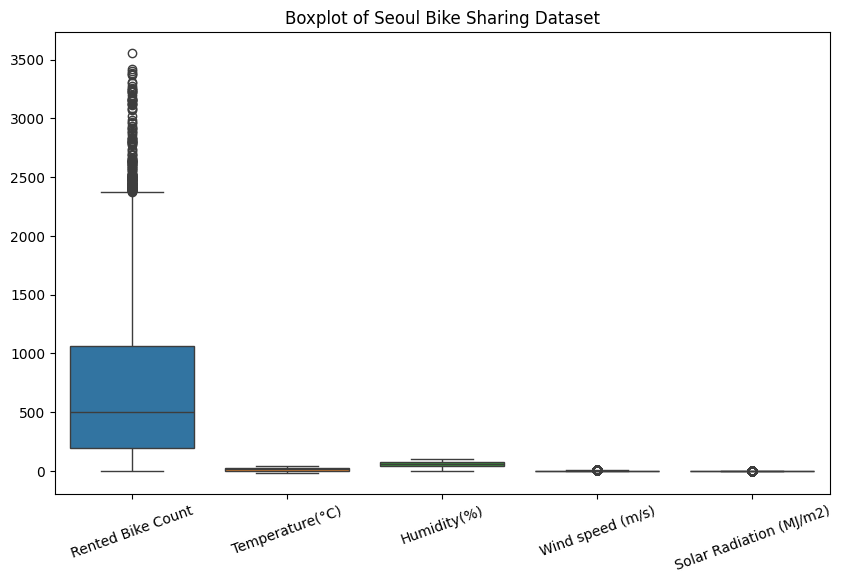

In [ ]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df[['Rented Bike Count', 'Temperature(°C)', 'Humidity(%)',
                     'Wind speed (m/s)', 'Solar Radiation (MJ/m2)']])
plt.title("Boxplot of Seoul Bike Sharing Dataset")
plt.xticks(rotation=20)
plt.show()

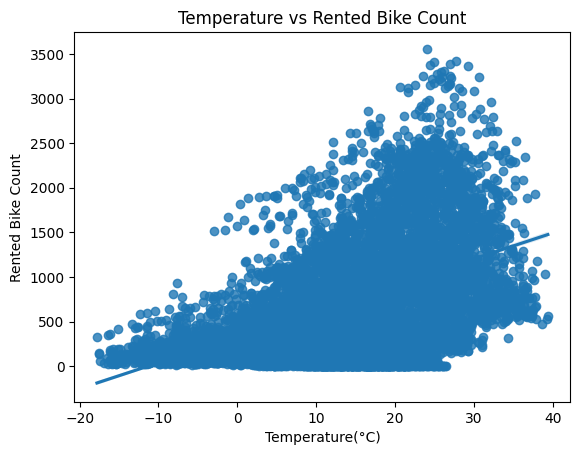

In [ ]:
sns.regplot(x=df['Temperature(°C)'], y=df['Rented Bike Count'])
plt.title("Temperature vs Rented Bike Count")
plt.show()

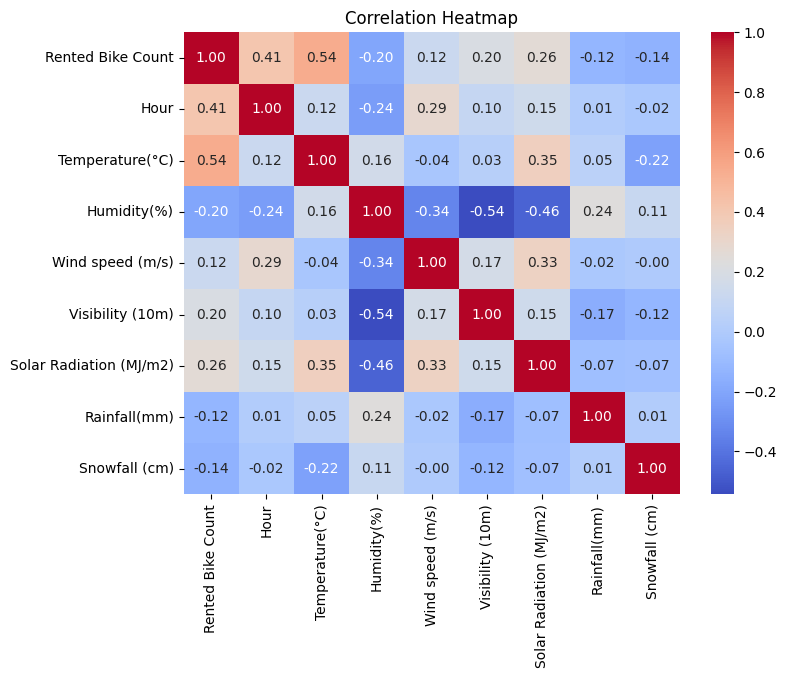

In [ ]:
plt.figure(figsize=(8,6))
corr = df[['Rented Bike Count', 'Hour', 'Temperature(°C)', 'Humidity(%)',
           'Wind speed (m/s)', 'Visibility (10m)', 'Solar Radiation (MJ/m2)',
           'Rainfall(mm)', 'Snowfall (cm)']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

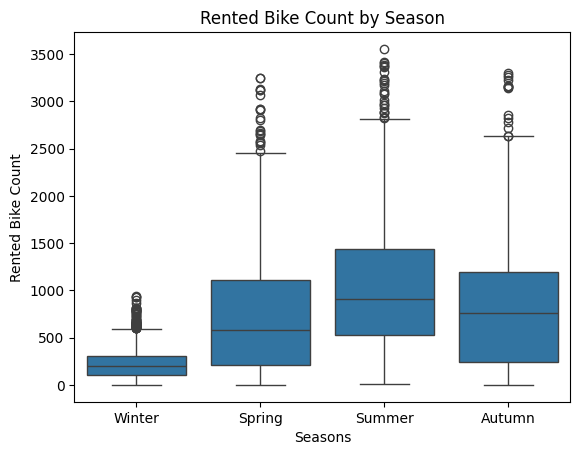

In [ ]:
sns.boxplot(data=df, x='Seasons', y='Rented Bike Count')
plt.title("Rented Bike Count by Season")
plt.show()

In [ ]:
columns = ['Rented Bike Count', 'Temperature(°C)', 'Humidity(%)',
           'Wind speed (m/s)', 'Solar Radiation (MJ/m2)']

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])
    df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])

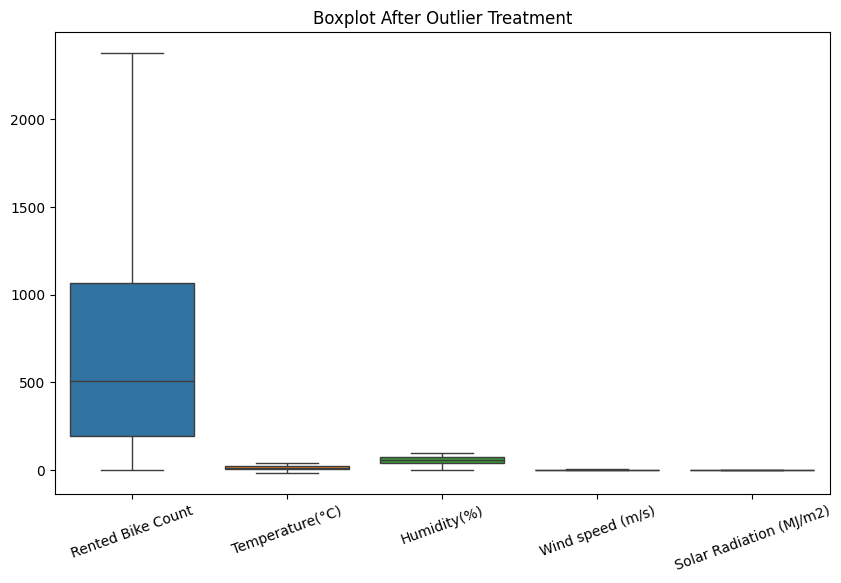

In [ ]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df[['Rented Bike Count', 'Temperature(°C)', 'Humidity(%)',
                     'Wind speed (m/s)', 'Solar Radiation (MJ/m2)']])
plt.title("Boxplot After Outlier Treatment")
plt.xticks(rotation=20)
plt.show()

In [ ]:
df.columns = df.columns.str.strip()

X = df.drop(columns=['Rented Bike Count', 'Date'])
y = df['Rented Bike Count']

X = pd.get_dummies(
    X,
    columns=X.select_dtypes(include='object').columns,
    dtype=int
)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

LinearRegression()

In [ ]:
linear_pred = linear_model.predict(X_test)

In [ ]:
linear_result = pd.DataFrame({
    'Actual': y_test,
    'Predicted': linear_pred
})

linear_result.head(10)

,Actual,Predicted
6056,1728.000,939.908471
5556,822.000,1191.603484
5990,658.000,1331.251473
7674,2376.625,1310.925884
3319,1083.000,547.738793
5761,636.000,777.186205
5972,1537.000,1457.882032
8758,712.000,1092.216878
6079,425.000,937.282181
7177,594.000,804.899345


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Linear Regression")
print("Mean Absolute Error:", mean_absolute_error(y_test, linear_pred))
print("Mean Squared Error:", mean_squared_error(y_test, linear_pred))
print("R2 Score:", r2_score(y_test, linear_pred))

Linear Regression
Mean Absolute Error: 322.5770642949536
Mean Squared Error: 178532.66686440512
R2 Score: 0.5460782626620051


In [ ]:
linear_train_accuracy = linear_model.score(X_train, y_train)
linear_test_accuracy = linear_model.score(X_test, y_test)

print("Training R2 Score:", linear_train_accuracy)
print("Testing R2 Score:", linear_test_accuracy)

Training R2 Score: 0.5662428255218814
Testing R2 Score: 0.5460782626620051


In [ ]:
from sklearn.ensemble import RandomForestRegressor

random_model = RandomForestRegressor(random_state=42)

random_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [ ]:
random_pred = random_model.predict(X_test)

In [ ]:
random_result = pd.DataFrame({
    'Actual': y_test,
    'Predicted': random_pred
})

random_result.head(10)

,Actual,Predicted
6056,1728.000,1631.4400
5556,822.000,724.4600
5990,658.000,682.2800
7674,2376.625,1944.7525
3319,1083.000,668.2700
5761,636.000,755.4900
5972,1537.000,1658.3700
8758,712.000,732.2300
6079,425.000,972.0600
7177,594.000,425.2300


In [ ]:
print("Random Forest Regression")
print("Mean Absolute Error:", mean_absolute_error(y_test, random_pred))
print("Mean Squared Error:", mean_squared_error(y_test, random_pred))
print("R2 Score:", r2_score(y_test, random_pred))

Random Forest Regression
Mean Absolute Error: 140.0963591609589
Mean Squared Error: 52562.85533068547
R2 Score: 0.8663582243507761


In [ ]:
random_train_accuracy = random_model.score(X_train, y_train)
random_test_accuracy = random_model.score(X_test, y_test)

print("Training R2 Score:", random_train_accuracy)
print("Testing R2 Score:", random_test_accuracy)

Training R2 Score: 0.9827454190957077
Testing R2 Score: 0.8663582243507761


In [ ]:
comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest Regression'],
    'MAE': [
        mean_absolute_error(y_test, linear_pred),
        mean_absolute_error(y_test, random_pred)
    ],
    'MSE': [
        mean_squared_error(y_test, linear_pred),
        mean_squared_error(y_test, random_pred)
    ],
    'R2 Score': [
        r2_score(y_test, linear_pred),
        r2_score(y_test, random_pred)
    ]
})

comparison

,Model,MAE,MSE,R2 Score
0,Linear Regression,322.577064,178532.666864,0.546078
1,Random Forest Regression,140.096359,52562.855331,0.866358


In [ ]:
new_bike = X_test.iloc[[0]]

linear_prediction = linear_model.predict(new_bike)
random_prediction = random_model.predict(new_bike)

print("Linear Regression Prediction:", linear_prediction[0])
print("Random Forest Prediction:", random_prediction[0])
print("Actual Rented Bike Count:", y_test.iloc[0])

Linear Regression Prediction: 939.9084705838586
Random Forest Prediction: 1631.44
Actual Rented Bike Count: 1728.0
